In [ ]:
pip install ultralytics h5py numpy opencv-python matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.3/41.3 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 37.1 MB/s eta 0:00:00


In [ ]:
import os
print(os.path.exists("best_segformer_b4.pth"))

False


In [ ]:
# Download the 6GB dataset directly from Zenodo
!wget -O s1s2_landslide_reference_data.zip \
https://zenodo.org/records/17007637/files/s1s2_landslide_reference_data.zip?download=1

--2026-06-23 18:08:59--  https://zenodo.org/records/17007637/files/s1s2_landslide_reference_data.zip?download=1
Resolving zenodo.org (zenodo.org)... 188.185.43.153, 188.184.103.118, 137.138.52.235, ...
Connecting to zenodo.org (zenodo.org)|188.185.43.153|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 5991736566 (5.6G) [application/octet-stream]
Saving to: ‘s1s2_landslide_reference_data.zip’

s1s2_landslide_refe 100%[===================>]   5.58G  14.5MB/s    in 6m 59s  

2026-06-23 18:15:58 (13.6 MB/s) - ‘s1s2_landslide_reference_data.zip’ saved [5991736566/5991736566]



In [ ]:
!unzip s1s2_landslide_reference_data.zip

Archive:  s1s2_landslide_reference_data.zip
   creating: s1s2_landslide_reference_data/
   creating: s1s2_landslide_reference_data/original_scenes/
   creating: s1s2_landslide_reference_data/original_scenes/BR0001/
  inflating: s1s2_landslide_reference_data/original_scenes/BR0001/BR0001__CDEM__None__DEM.tif  
  inflating: s1s2_landslide_reference_data/original_scenes/BR0001/BR0001__CDEM__None__SLOPE.tif  
  inflating: s1s2_landslide_reference_data/original_scenes/BR0001/BR0001__files_meta.csv  
  inflating: s1s2_landslide_reference_data/original_scenes/BR0001/BR0001__None__None__MASK.tif  
  inflating: s1s2_landslide_reference_data/original_scenes/BR0001/BR0001__S1SLC__2018-12-29_2019-01-10__DES_COHVV.tif  
  inflating: s1s2_landslide_reference_data/original_scenes/BR0001/BR0001__S1SLC__2018-12-29__DES_ALPHA.tif  
  inflating: s1s2_landslide_reference_data/original_scenes/BR0001/BR0001__S1SLC__2018-12-29__DES_ANISOTROPY.tif  
  inflating: s1s2_landslide_reference_data/original_scenes/B

In [ ]:
import h5py

path = "/content/s1s2_landslide_reference_data/reference_data/train_n3_s1s2.h5"

with h5py.File(path, "r") as f:
    print("Keys:", list(f.keys()))

    for k in f.keys():
        print(k, f[k].shape, f[k].dtype)

Keys: ['None_DEM', 'None_MASK', 'None_SLOPE', 'POST1_ALPHA', 'POST1_ANISOTROPY', 'POST1_B02', 'POST1_B03', 'POST1_B04', 'POST1_B05', 'POST1_B06', 'POST1_B07', 'POST1_B08', 'POST1_B11', 'POST1_B12', 'POST1_B8A', 'POST1_COHVV', 'POST1_ENTROPY', 'POST1_NDVI', 'POST1_gVH', 'POST1_gVV', 'POST2_ALPHA', 'POST2_ANISOTROPY', 'POST2_COHVV', 'POST2_ENTROPY', 'POST2_gVH', 'POST2_gVV', 'POST3_ALPHA', 'POST3_ANISOTROPY', 'POST3_COHVV', 'POST3_ENTROPY', 'POST3_gVH', 'POST3_gVV', 'PRE1_ALPHA', 'PRE1_ANISOTROPY', 'PRE1_B02', 'PRE1_B03', 'PRE1_B04', 'PRE1_B05', 'PRE1_B06', 'PRE1_B07', 'PRE1_B08', 'PRE1_B11', 'PRE1_B12', 'PRE1_B8A', 'PRE1_COHVV', 'PRE1_ENTROPY', 'PRE1_NDVI', 'PRE1_gVH', 'PRE1_gVV', 'PRE2_ALPHA', 'PRE2_ANISOTROPY', 'PRE2_COHVV', 'PRE2_ENTROPY', 'PRE2_gVH', 'PRE2_gVV', 'PRE3_ALPHA', 'PRE3_ANISOTROPY', 'PRE3_ENTROPY', 'PRE3_gVH', 'PRE3_gVV']
None_DEM (355, 1, 128, 128) float32
None_MASK (355, 1, 128, 128) float32
None_SLOPE (355, 1, 128, 128) float32
POST1_ALPHA (355, 1, 128, 128) float32
P

In [ ]:
!pip install -q transformers timm evaluate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 5.2 MB/s eta 0:00:00


Imports

In [ ]:
import h5py
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader

from transformers import SegformerForSemanticSegmentation

from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import jaccard_score

from tqdm import tqdm

Dataset Loader

In [ ]:
class LandslideDataset(Dataset):

    def __init__(self, h5_path):

        self.h5_path = h5_path

        with h5py.File(h5_path, "r") as f:
            self.length = f["None_MASK"].shape[0]

    def __len__(self):
        return self.length

    def __getitem__(self, idx):

        with h5py.File(self.h5_path, "r") as f:

            red = f["POST1_B04"][idx,0]
            green = f["POST1_B03"][idx,0]
            blue = f["POST1_B02"][idx,0]

            mask = f["None_MASK"][idx,0]

        image = np.stack(
            [red, green, blue],
            axis=0
        )

        image = image.astype(np.float32)

        image = (
            image - image.min()
        ) / (
            image.max() - image.min() + 1e-8
        )

        mask = (mask > 0).astype(np.int64)

        return (
            torch.tensor(image),
            torch.tensor(mask)
        )

Paths

In [ ]:
train_path = "/content/s1s2_landslide_reference_data/reference_data/train_n3_s1s2.h5"

val_path = "/content/s1s2_landslide_reference_data/reference_data/val_n3_s1s2.h5"

test_path = "/content/s1s2_landslide_reference_data/reference_data/testind_n3_s1s2.h5"

Dataloaders

In [ ]:
train_dataset = LandslideDataset(train_path)
val_dataset = LandslideDataset(val_path)
test_dataset = LandslideDataset(test_path)

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2
)

SegFormer-B4

In [ ]:
model = SegformerForSemanticSegmentation.from_pretrained(
    "nvidia/segformer-b4-finetuned-ade-512-512",
    num_labels=2,
    ignore_mismatched_sizes=True
)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:124: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/6.89k [00:00<?, ?B/s]

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `150`.


pytorch_model.bin:   0%|          | 0.00/257M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/257M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/930 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/segformer-b4-finetuned-ade-512-512
Key                           | Status   |                                                                                                     
------------------------------+----------+-----------------------------------------------------------------------------------------------------
decode_head.classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150]) vs model:torch.Size([2])                      
decode_head.classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150, 768, 1, 1]) vs model:torch.Size([2, 768, 1, 1])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Device

In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model.to(device)

SegformerForSemanticSegmentation(
  (segformer): SegformerModel(
    (stages): ModuleList(
      (0): SegformerStage(
        (patch_embeddings): SegformerOverlapPatchEmbeddings(
          (proj): Conv2d(3, 64, kernel_size=(7, 7), stride=(4, 4), padding=(3, 3))
          (layer_norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
        )
        (blocks): ModuleList(
          (0): SegformerLayer(
            (layernorm_before): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
            (attention): SegformerAttention(
              (q_proj): Linear(in_features=64, out_features=64, bias=True)
              (k_proj): Linear(in_features=64, out_features=64, bias=True)
              (v_proj): Linear(in_features=64, out_features=64, bias=True)
              (o_proj): Linear(in_features=64, out_features=64, bias=True)
              (sequence_reduction): SegformerSequenceReduction(
                (sequence_reduction): Conv2d(64, 64, kernel_size=(8, 8), stride=(8, 8))
        

Loss

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class DiceBCELoss(nn.Module):
    def __init__(self, dice_weight=0.7, bce_weight=0.3):
        super().__init__()
        self.dice_weight = dice_weight
        self.bce_weight = bce_weight

    def forward(self, logits, targets):

        # logits: [B,2,H,W]
        # targets: [B,H,W]

        targets = targets.float()

        # Foreground (landslide) logit
        fg_logits = logits[:, 1, :, :]

        # BCE Loss
        bce_loss = F.binary_cross_entropy_with_logits(
            fg_logits,
            targets
        )

        # Dice Loss
        probs = torch.sigmoid(fg_logits)

        smooth = 1e-6

        intersection = (probs * targets).sum(dim=(1, 2))

        union = (
            probs.sum(dim=(1, 2))
            + targets.sum(dim=(1, 2))
        )

        dice = (
            2.0 * intersection + smooth
        ) / (
            union + smooth
        )

        dice_loss = 1 - dice.mean()

        total_loss = (
            self.bce_weight * bce_loss
            + self.dice_weight * dice_loss
        )

        return total_loss


criterion = DiceBCELoss(
    dice_weight=0.7,
    bce_weight=0.3
)

Optimizer

In [ ]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=0.01
)

Validation Function

In [ ]:
def evaluate(model, loader):

    model.eval()

    all_preds = []
    all_masks = []

    with torch.no_grad():

        for images, masks in loader:

            images = images.to(device)
            masks = masks.to(device)

            outputs = model(
                pixel_values=images
            )

            logits = outputs.logits

            logits = F.interpolate(
                logits,
                size=masks.shape[-2:],
                mode="bilinear",
                align_corners=False
            )

            preds = torch.argmax(
                logits,
                dim=1
            )

            all_preds.extend(
                preds.cpu().numpy().flatten()
            )

            all_masks.extend(
                masks.cpu().numpy().flatten()
            )

    precision = precision_score(
        all_masks,
        all_preds,
        zero_division=0
    )

    recall = recall_score(
        all_masks,
        all_preds,
        zero_division=0
    )

    f1 = f1_score(
        all_masks,
        all_preds,
        zero_division=0
    )

    iou = jaccard_score(
        all_masks,
        all_preds,
        zero_division=0
    )

    return precision, recall, f1, iou

Training Loop

In [ ]:
best_iou = 0

for epoch in range(25):

    model.train()

    running_loss = 0

    loop = tqdm(train_loader)

    for images, masks in loop:

        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        outputs = model(
            pixel_values=images
        )

        logits = outputs.logits

        logits = F.interpolate(
            logits,
            size=masks.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        loss = criterion(
            logits,
            masks
        )

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        loop.set_description(
            f"Epoch {epoch+1}"
        )

        loop.set_postfix(
            loss=loss.item()
        )

    precision, recall, f1, iou = evaluate(
        model,
        val_loader
    )

    print(
        f"\nEpoch {epoch+1}"
    )

    print(
        f"Precision={precision:.4f}"
    )

    print(
        f"Recall={recall:.4f}"
    )

    print(
        f"F1={f1:.4f}"
    )

    print(
        f"IoU={iou:.4f}"
    )

    if iou > best_iou:

        best_iou = iou

        torch.save(
            model.state_dict(),
            "best_segformer_b4.pth"
        )

        print(
            "Best model saved"
        )

Epoch 1: 100%|██████████| 23/23 [00:13<00:00,  1.65it/s, loss=0.723]



Epoch 1
Precision=0.5215
Recall=0.9075
F1=0.6624
IoU=0.4952
Best model saved


Epoch 2: 100%|██████████| 23/23 [00:08<00:00,  2.81it/s, loss=0.701]



Epoch 2
Precision=0.4794
Recall=0.8766
F1=0.6198
IoU=0.4491


Epoch 3: 100%|██████████| 23/23 [00:07<00:00,  3.04it/s, loss=0.63]


...


Epoch 23
Precision=0.9284
Recall=0.9371
F1=0.9327
IoU=0.8739
Best model saved


Epoch 24: 100%|██████████| 23/23 [00:07<00:00,  2.89it/s, loss=0.273]



Epoch 24
Precision=0.9212
Recall=0.9415
F1=0.9312
IoU=0.8713


Epoch 25: 100%|██████████| 23/23 [00:07<00:00,  2.92it/s, loss=0.123]



Epoch 25
Precision=0.9277
Recall=0.9383
F1=0.9330
IoU=0.8744
Best model saved


In [ ]:
model.load_state_dict(
    torch.load(
        "best_segformer_b4.pth"
    )
)

precision, recall, f1, iou = evaluate(
    model,
    test_loader
)

print("\nTEST RESULTS")

print("Precision:", precision)
print("Recall:", recall)
print("F1:", f1)
print("IoU:", iou)


TEST RESULTS
Precision: 0.8539160212724943
Recall: 0.8600502512562814
F1: 0.8569721591588003
IoU: 0.7497386577461844


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    jaccard_score
)

def evaluate(model, loader):

    model.eval()

    all_preds = []
    all_masks = []

    with torch.no_grad():

        for images, masks in loader:

            images = images.to(device)
            masks = masks.to(device)

            outputs = model(
                pixel_values=images
            )

            logits = outputs.logits

            logits = F.interpolate(
                logits,
                size=masks.shape[-2:],
                mode="bilinear",
                align_corners=False
            )

            preds = torch.argmax(
                logits,
                dim=1
            )

            all_preds.extend(
                preds.cpu().numpy().flatten()
            )

            all_masks.extend(
                masks.cpu().numpy().flatten()
            )

    accuracy = accuracy_score(
        all_masks,
        all_preds
    )

    precision = precision_score(
        all_masks,
        all_preds,
        zero_division=0
    )

    recall = recall_score(
        all_masks,
        all_preds,
        zero_division=0
    )

    f1 = f1_score(
        all_masks,
        all_preds,
        zero_division=0
    )

    iou = jaccard_score(
        all_masks,
        all_preds,
        zero_division=0
    )

    return accuracy, precision, recall, f1, iou

In [ ]:
accuracy, precision, recall, f1, iou = evaluate(
    model,
    test_loader
)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1       : {f1:.4f}")
print(f"IoU      : {iou:.4f}")

Accuracy : 0.9651
Precision: 0.8539
Recall   : 0.8601
F1       : 0.8570
IoU      : 0.7497


In [ ]:
train_precision, train_recall, train_f1, train_iou = evaluate(
    model,
    train_loader
)

val_precision, val_recall, val_f1, val_iou = evaluate(
    model,
    val_loader
)

print(f"\nEpoch {epoch+1}")

print("\nTRAIN")
print(f"Precision: {train_precision:.4f}")
print(f"Recall:    {train_recall:.4f}")
print(f"F1:        {train_f1:.4f}")
print(f"IoU:       {train_iou:.4f}")

print("\nVALIDATION")
print(f"Precision: {val_precision:.4f}")
print(f"Recall:    {val_recall:.4f}")
print(f"F1:        {val_f1:.4f}")
print(f"IoU:       {val_iou:.4f}")


Epoch 25

TRAIN
Precision: 0.9475
Recall:    0.9583
F1:        0.9529
IoU:       0.9100

VALIDATION
Precision: 0.9277
Recall:    0.9383
F1:        0.9330
IoU:       0.8744


In [ ]:
import torch
import matplotlib.pyplot as plt
import numpy as np

def visualize_predictions(model, dataloader, device, num_samples=3):

    model.eval()

    with torch.no_grad():

        images, masks = next(iter(dataloader))

        images = images.to(device)
        masks = masks.to(device)

        logits = model(images)

        if isinstance(logits, dict):
            logits = logits["out"]

        preds = torch.argmax(logits, dim=1)

        n = min(num_samples, images.shape[0])

        fig, axes = plt.subplots(
            n,
            4,
            figsize=(16, 4*n)
        )

        if n == 1:
            axes = np.expand_dims(axes, axis=0)

        for i in range(n):

            # Input image
            img = images[i].cpu().permute(1,2,0).numpy()

            img = (img - img.min()) / (img.max() - img.min() + 1e-8)

            gt = masks[i].cpu().numpy()

            pred = preds[i].cpu().numpy()

            # Overlay
            overlay = img.copy()

            red_mask = pred == 1

            overlay[red_mask] = (
                0.6 * overlay[red_mask]
                + 0.4 * np.array([1,0,0])
            )

            axes[i,0].imshow(img)
            axes[i,0].set_title("Input Image")
            axes[i,0].axis("off")

            axes[i,1].imshow(gt,cmap="gray")
            axes[i,1].set_title("Ground Truth Mask")
            axes[i,1].axis("off")

            axes[i,2].imshow(pred,cmap="gray")
            axes[i,2].set_title("Predicted Mask")
            axes[i,2].axis("off")

            axes[i,3].imshow(overlay)
            axes[i,3].set_title("Overlay (Red = Landslide)")
            axes[i,3].axis("off")

        plt.tight_layout()
        plt.show()

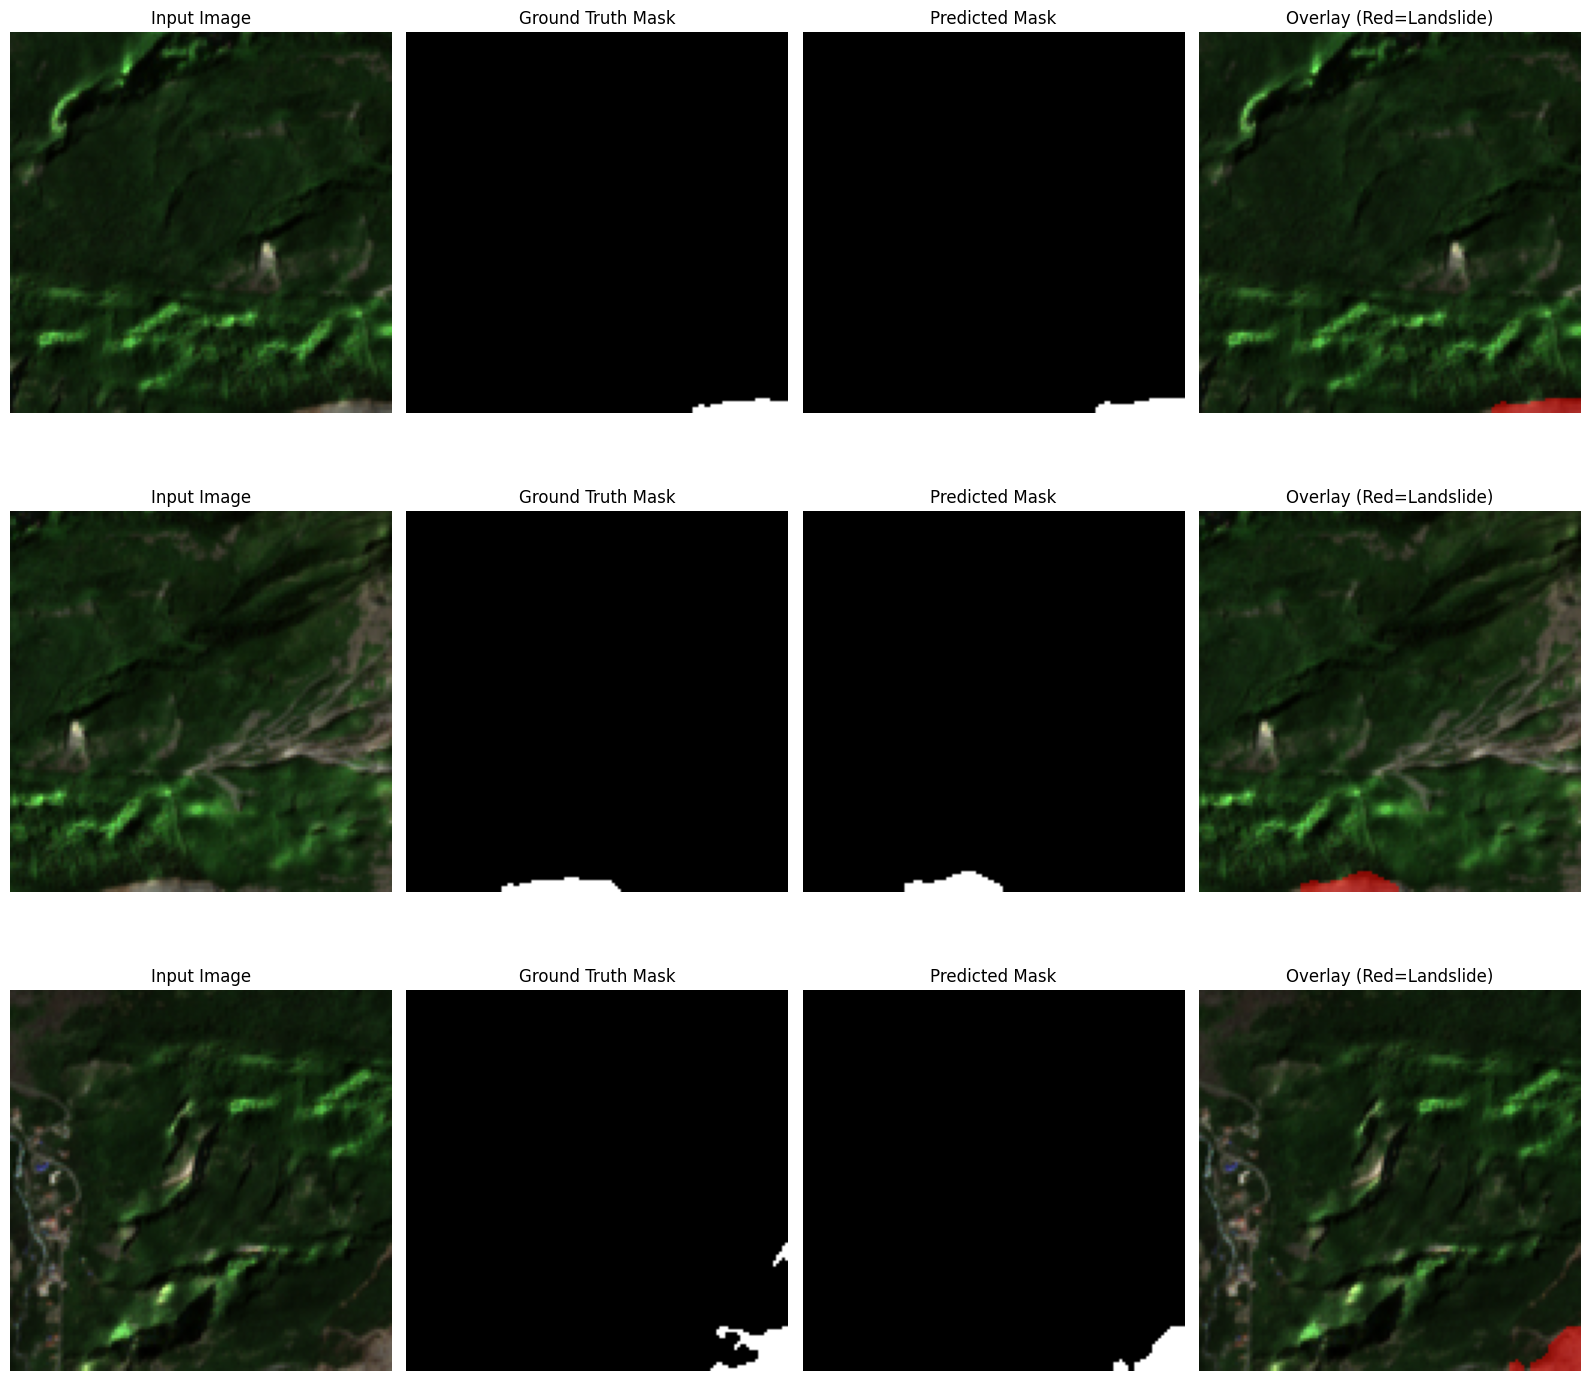

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torch.nn.functional as F

batch = next(iter(test_loader))

images = batch[0].to(device)
masks  = batch[1].to(device)

with torch.no_grad():

    outputs = model(images)

    logits = F.interpolate(
        outputs.logits,
        size=masks.shape[-2:],
        mode="bilinear",
        align_corners=False
    )

    preds = torch.argmax(logits, dim=1)

num_samples = 3

fig, axes = plt.subplots(num_samples, 4, figsize=(16, 5*num_samples))

for i in range(num_samples):

    img = images[i].cpu().permute(1,2,0).numpy()
    img = (img - img.min())/(img.max()-img.min()+1e-8)

    gt = masks[i].cpu().numpy()
    pred = preds[i].cpu().numpy()

    overlay = img.copy()

    overlay[pred == 1] = (
        0.5 * overlay[pred == 1]
        + 0.5 * np.array([1,0,0])
    )

    axes[i,0].imshow(img)
    axes[i,0].set_title("Input Image")
    axes[i,0].axis("off")

    axes[i,1].imshow(gt, cmap="gray")
    axes[i,1].set_title("Ground Truth Mask")
    axes[i,1].axis("off")

    axes[i,2].imshow(pred, cmap="gray")
    axes[i,2].set_title("Predicted Mask")
    axes[i,2].axis("off")

    axes[i,3].imshow(overlay)
    axes[i,3].set_title("Overlay (Red=Landslide)")
    axes[i,3].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
#NEW
testspt_path = "/content/s1s2_landslide_reference_data/reference_data/testspt_n3_s1s2.h5"

testspt_dataset = LandslideDataset(testspt_path)

testspt_loader = DataLoader(
    testspt_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2
)

In [ ]:
spt_accuracy, spt_precision, spt_recall, spt_f1, spt_iou = evaluate(
    model,
    testspt_loader
)

print("\nSPATIAL TEST RESULTS")
print("Accuracy: ", spt_accuracy)
print("Precision:", spt_precision)
print("Recall:", spt_recall)
print("F1:", spt_f1)
print("IoU:", spt_iou)

ValueError: not enough values to unpack (expected 5, got 4)

In [ ]:
import h5py

with h5py.File(testspt_path, "r") as f:
    spt_masks = f["None_MASK"][:, 0]  # shape: (num_patches, 128, 128)

N = spt_masks.size                          # total pixels in spatial test set
P = int((spt_masks > 0).sum())              # total actual landslide pixels (ground truth positives)

TP = spt_recall * P
FN = P - TP
FP = (TP / spt_precision) - TP if spt_precision > 0 else 0
TN = N - TP - FN - FP

spt_accuracy = (TP + TN) / N

print("SPATIAL TEST ACCURACY:", spt_accuracy)

NameError: name 'spt_recall' is not defined

confusion metrics

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    all_masks,
    all_preds
)

print(cm)

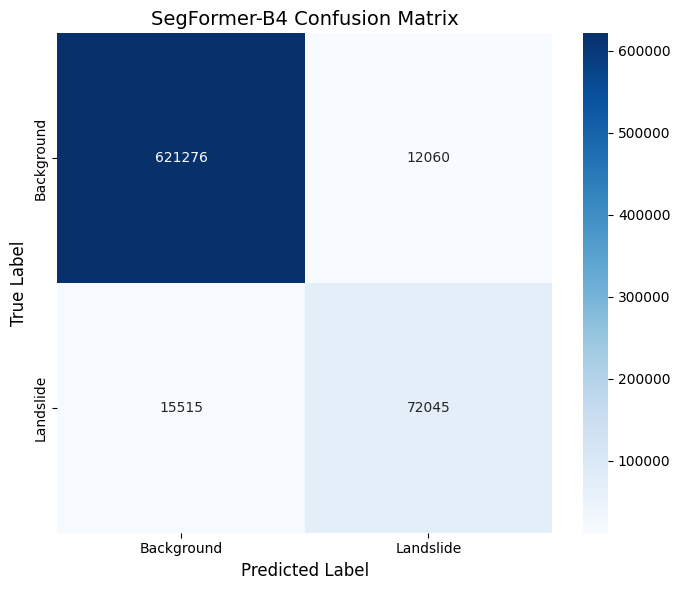

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

cm = np.array([
    [621276, 12060],
    [15515, 72045]
])

plt.figure(figsize=(7,6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Background', 'Landslide'],
    yticklabels=['Background', 'Landslide']
)

plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.title('SegFormer-B4 Confusion Matrix', fontsize=14)

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(
    classification_report(
        all_masks,
        all_preds,
        target_names=[
            "Background",
            "Landslide"
        ]
    )
)